# Preseason Dry-Run: Data Pulls & CLV Analysis

Working notebook for inspecting live-collected odds data and running quick analysis
during the preseason dry run (`src/collect/preseason.py` -> `src/clv/preseason_report.py`).
Full context and caveats live in the repo README's **"Preseason dry run"** and
**"Data chronology"** sections -- read those first if anything here is confusing.

**tl;dr on what this data is (and isn't):**
- Real preseason odds from FanDuel, MyBookie, and 1xBet (no Pinnacle -- confirmed live,
  see README).
- Stored separately from the real season (`data/snapshots_preseason/` vs.
  `data/snapshots/`), event_ids prefixed `PRE` so they can't be confused with a real
  nflverse `game_id`.
- **Not bet on, not the paper's result.** This is infrastructure validation -- proving
  the poll -> match -> store -> measure pipeline works on live data before Week 1.

Re-run this notebook top to bottom any time after a new `make preseason-poll` to pull in
fresh data -- nothing here is cached beyond what's already written to disk.

In [1]:
from pathlib import Path
from datetime import UTC, datetime

import pandas as pd

# Notebook lives in notebooks/, one level below the repo root.
ROOT = Path("..").resolve()
assert (ROOT / "pyproject.toml").exists(), f"unexpected repo root: {ROOT}"

from src.store.pit_store import PointInTimeStore
from src.clv.preseason_report import clv_movement_report

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

## Opening a snapshot parquet file directly

Every poll writes one immutable parquet file per batch, under
`data/snapshots_preseason/capture_date=YYYY-MM-DD/<timestamp>_<uuid>.parquet`. For a
one-off peek at a single file, plain pandas is enough:

```python
pd.read_parquet("data/snapshots_preseason/capture_date=2026-08-17/<filename>.parquet")
```

For real analysis, use `PointInTimeStore` instead (below) -- it reads and concatenates
every file under the root in one call, which is what you want once there's more than one
poll's worth of data on disk.

In [2]:
preseason_root = ROOT / "data" / "snapshots_preseason"
files = sorted(preseason_root.glob("**/*.parquet"))
print(f"{len(files)} snapshot file(s) on disk:")
for f in files:
    print(" ", f.relative_to(preseason_root))

2 snapshot file(s) on disk:
  capture_date=2026-08-17/20260817T074421904770_56d51ddd.parquet
  capture_date=2026-08-17/20260817T080421859571_007c96d4.parquet


## Raw snapshots -- preseason store

`PointInTimeStore.read_as_of(decision_time)` returns every row captured at or before
`decision_time`. Passing "now" (as below) is correct here -- this is a live-monitoring
read, not a backtest, so there's no leakage concern the way there would be inside
`src/backtest/engine.py`.

In [3]:
preseason_store = PointInTimeStore(root=preseason_root)
raw = preseason_store.read_as_of(datetime.now(UTC))

print(f"{len(raw)} rows, {raw['event_id'].nunique()} distinct games, "
      f"{raw['capture_time'].nunique()} distinct poll timestamp(s)")
raw.head()

504 rows, 16 distinct games, 2 distinct poll timestamp(s)


,capture_time,event_id,season,week,home_team,away_team,event_start_time,book,market,side,line,price_american,price_decimal,implied_prob_raw
0,2026-08-17 07:44:21.895206+00:00,2026_PRE_a697012ab3bb18d3549ff1bce61ed4da,2026,0,HOU,LV,2026-08-21 00:00:00+00:00,fanduel,moneyline,home,NaN,-102,1.980392,0.504950
1,2026-08-17 07:44:21.895206+00:00,2026_PRE_a697012ab3bb18d3549ff1bce61ed4da,2026,0,HOU,LV,2026-08-21 00:00:00+00:00,fanduel,moneyline,away,NaN,-116,1.862069,0.537037
2,2026-08-17 07:44:21.895206+00:00,2026_PRE_a697012ab3bb18d3549ff1bce61ed4da,2026,0,HOU,LV,2026-08-21 00:00:00+00:00,fanduel,spread,home,1.5,-118,1.847458,0.541284
3,2026-08-17 07:44:21.895206+00:00,2026_PRE_a697012ab3bb18d3549ff1bce61ed4da,2026,0,HOU,LV,2026-08-21 00:00:00+00:00,fanduel,spread,away,-1.5,-104,1.961538,0.509804
4,2026-08-17 07:44:21.895206+00:00,2026_PRE_a697012ab3bb18d3549ff1bce61ed4da,2026,0,HOU,LV,2026-08-21 00:00:00+00:00,fanduel,total,over,37.5,-115,1.869565,0.534884


In [4]:
raw.groupby(["book", "market"]).size().unstack(fill_value=0)

market,moneyline,spread,total
book,,,
fanduel,64,64,64
mybookieag,64,60,64
onexbet,0,60,64


## Games currently tracked

In [5]:
games = (
    raw[["event_id", "home_team", "away_team", "event_start_time"]]
    .drop_duplicates()
    .sort_values("event_start_time")
    .reset_index(drop=True)
)
games

,event_id,home_team,away_team,event_start_time
0,2026_PRE_a697012ab3bb18d3549ff1bce61ed4da,HOU,LV,2026-08-21 00:00:00+00:00
1,2026_PRE_6ed9b1b3e1ef423b7ae7754c92337dd5,LAC,SF,2026-08-21 02:00:00+00:00
2,2026_PRE_f8e76a773e6d82162152b4196fb0c058,PIT,NYJ,2026-08-21 23:00:00+00:00
3,2026_PRE_db3848dd2679930aea82262ca929dc1f,JAX,CAR,2026-08-21 23:30:00+00:00
4,2026_PRE_7482152240304f8808316d22943c7345,DEN,GB,2026-08-22 01:00:00+00:00
5,2026_PRE_d1f28aaebc2721f3966582b9041e3da0,DET,WAS,2026-08-22 16:00:00+00:00
6,2026_PRE_d93bfc969d95e6764567074282ab971a,IND,ATL,2026-08-22 17:00:00+00:00
7,2026_PRE_be0d79220b3be1adf04a6d010c7e0f54,MIN,BAL,2026-08-22 17:00:00+00:00
8,2026_PRE_7e346b13c17e63d081332574839ca53f,CLE,BUF,2026-08-22 17:00:00+00:00
9,2026_PRE_b1293da5b4e1871d41005cbf4a087240,LA,NO,2026-08-22 20:00:00+00:00


## CLV movement report

Entry (earliest snapshot) vs. latest snapshot captured so far, per game, FanDuel
moneyline only (the reference book -- see `src/clv/preseason_report.py`). A game only
shows up here once it's been polled at least twice; run `make preseason-poll` again and
re-run this cell to pull in more games as movement accrues.

In [6]:
report = clv_movement_report(preseason_store)
if report.empty:
    print("No games with >=2 snapshots yet. Run `make preseason-poll` again, then re-run this cell.")
else:
    display(report.sort_values("close_time"))

,event_id,home_team,away_team,n_snapshots,entry_time,close_time,home_price_clv,away_price_clv,home_prob_clv,away_prob_clv
0,2026_PRE_06caa9f04333a22dc22a4f934e0aa8f5,NE,PHI,2,2026-08-17 07:44:21.895206+00:00,2026-08-17 08:04:21.850201+00:00,-0.016265,0.009612,-0.006487,0.006487
1,2026_PRE_5660866f23bd706914fb55c61cc6b2b0,ARI,DAL,2,2026-08-17 07:44:21.895206+00:00,2026-08-17 08:04:21.850201+00:00,0.000000,0.000000,0.000000,0.000000
2,2026_PRE_663d2a6d60bc7e4ee8b599db2bd9de2f,CIN,CHI,2,2026-08-17 07:44:21.895206+00:00,2026-08-17 08:04:21.850201+00:00,0.000000,0.000000,0.000000,0.000000
3,2026_PRE_6ed9b1b3e1ef423b7ae7754c92337dd5,LAC,SF,2,2026-08-17 07:44:21.895206+00:00,2026-08-17 08:04:21.850201+00:00,0.000000,0.000000,0.000000,0.000000
4,2026_PRE_7482152240304f8808316d22943c7345,DEN,GB,2,2026-08-17 07:44:21.895206+00:00,2026-08-17 08:04:21.850201+00:00,0.000000,0.000000,0.000000,0.000000
5,2026_PRE_7e346b13c17e63d081332574839ca53f,CLE,BUF,2,2026-08-17 07:44:21.895206+00:00,2026-08-17 08:04:21.850201+00:00,0.000000,0.000000,0.000000,0.000000
6,2026_PRE_a697012ab3bb18d3549ff1bce61ed4da,HOU,LV,2,2026-08-17 07:44:21.895206+00:00,2026-08-17 08:04:21.850201+00:00,0.000000,0.000000,0.000000,0.000000
7,2026_PRE_b1293da5b4e1871d41005cbf4a087240,LA,NO,2,2026-08-17 07:44:21.895206+00:00,2026-08-17 08:04:21.850201+00:00,0.000000,0.000000,0.000000,0.000000
8,2026_PRE_be0d79220b3be1adf04a6d010c7e0f54,MIN,BAL,2,2026-08-17 07:44:21.895206+00:00,2026-08-17 08:04:21.850201+00:00,0.000000,0.000000,0.000000,0.000000
9,2026_PRE_d1f28aaebc2721f3966582b9041e3da0,DET,WAS,2,2026-08-17 07:44:21.895206+00:00,2026-08-17 08:04:21.850201+00:00,0.040016,-0.045872,0.021349,-0.021349


## Line movement chart (FanDuel moneyline, fair probability)

One panel per game that's been polled at least twice. Home and away get fixed colors
(dataviz skill's categorical slots 1 and 2 -- blue/orange, adjacent-pair CVD-validated),
one y-axis (fair win probability, devigged via `market_baseline`), legend instead of
per-point labels.

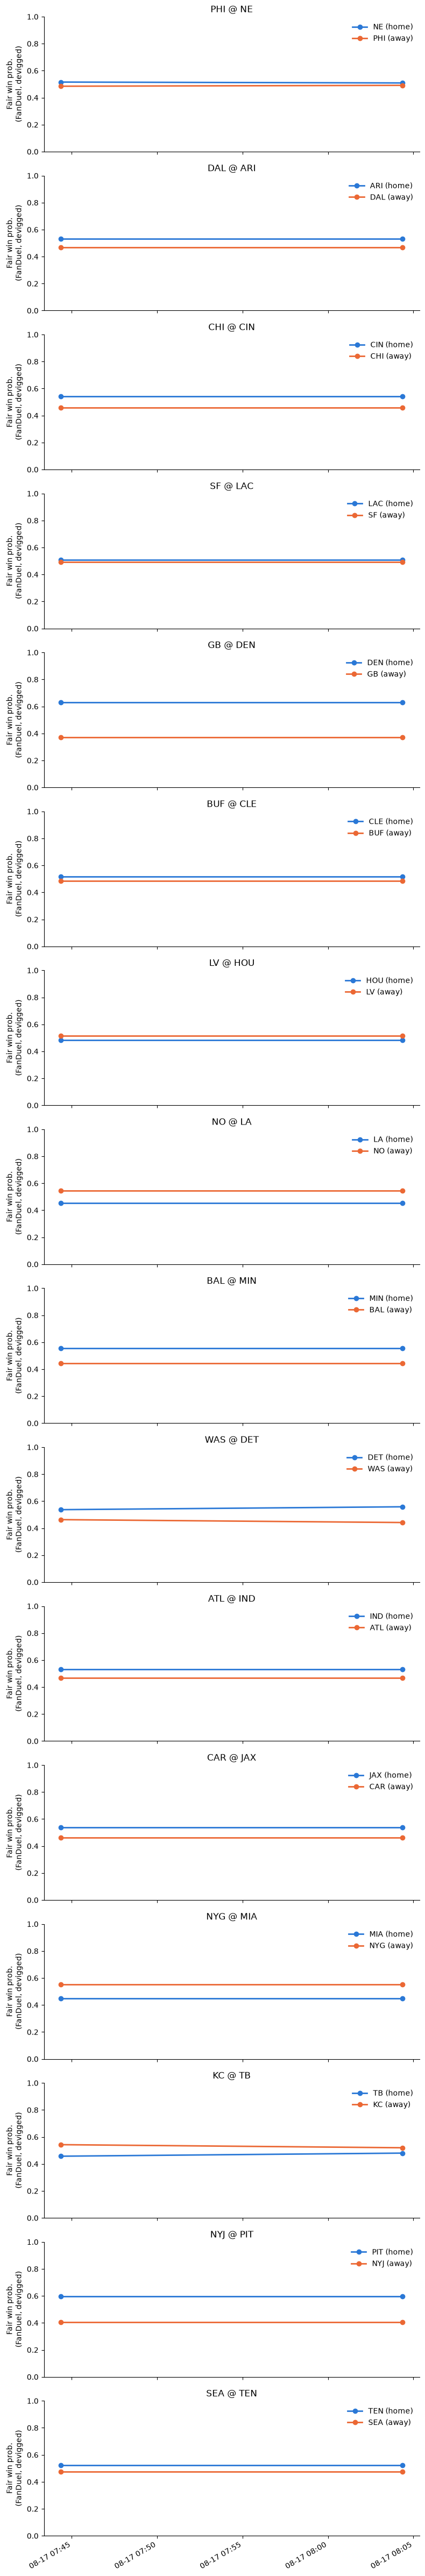

In [7]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

from src.model.baseline import market_baseline

HOME_COLOR = "#2a78d6"  # dataviz skill categorical slot 1
AWAY_COLOR = "#eb6834"  # dataviz skill categorical slot 2

fd = raw[(raw["book"] == "fanduel") & (raw["market"] == "moneyline")]
events_with_movement = [eid for eid, g in fd.groupby("event_id") if g["capture_time"].nunique() >= 2]

if not events_with_movement:
    print("No game has >=2 FanDuel moneyline polls yet -- nothing to chart. Poll again later.")
else:
    n = len(events_with_movement)
    fig, axes = plt.subplots(n, 1, figsize=(8, 3 * n))
    axes = [axes] if n == 1 else list(axes)

    for ax, event_id in zip(axes, events_with_movement, strict=True):
        g = fd[fd["event_id"] == event_id].sort_values("capture_time")
        home_team, away_team = g["home_team"].iloc[0], g["away_team"].iloc[0]

        times, home_probs, away_probs = [], [], []
        for t, gt in g.groupby("capture_time"):
            home_price = gt.loc[gt["side"] == "home", "price_american"]
            away_price = gt.loc[gt["side"] == "away", "price_american"]
            if home_price.empty or away_price.empty:
                continue
            times.append(t)
            odds = [int(home_price.iloc[0]), int(away_price.iloc[0])]
            home_probs.append(market_baseline(odds, side_index=0))
            away_probs.append(market_baseline(odds, side_index=1))

        ax.plot(times, home_probs, marker="o", markersize=6, linewidth=2, color=HOME_COLOR, label=f"{home_team} (home)")
        ax.plot(times, away_probs, marker="o", markersize=6, linewidth=2, color=AWAY_COLOR, label=f"{away_team} (away)")
        ax.set_ylim(0, 1)
        ax.set_ylabel("Fair win prob.\n(FanDuel, devigged)")
        ax.set_title(f"{away_team} @ {home_team}")
        ax.legend(loc="best", frameon=False)
        ax.spines[["top", "right"]].set_visible(False)
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d %H:%M"))

    fig.autofmt_xdate()
    fig.tight_layout()
    plt.show()

## Historical (nflverse) data -- for model reference, not live

Separate provenance from everything above: this is the 2015-2024 static pull used to
train/calibrate the win-probability model (`src/model/train.py`,
`src/model/calibration.py`), not confirmed-Pinnacle, not live. See README's "Data
chronology" section before conflating this with the preseason data above.

In [8]:
schedule = pd.read_parquet(ROOT / "data" / "static" / "schedules_2015_2024.parquet")
pbp = pd.read_parquet(ROOT / "data" / "static" / "pbp_2015_2024.parquet")
print("schedule:", schedule.shape, "  pbp:", pbp.shape)
schedule.head()

schedule: (2743, 46)   pbp: (483605, 12)


,game_id,season,game_type,week,gameday,weekday,gametime,away_team,away_score,home_team,home_score,location,result,total,overtime,old_game_id,gsis,nfl_detail_id,pfr,pff,espn,ftn,away_rest,home_rest,away_moneyline,home_moneyline,spread_line,away_spread_odds,home_spread_odds,total_line,under_odds,over_odds,div_game,roof,surface,temp,wind,away_qb_id,home_qb_id,away_qb_name,home_qb_name,away_coach,home_coach,referee,stadium_id,stadium
0,2015_01_PIT_NE,2015,REG,1,2015-09-10,Thursday,20:30,PIT,21,NE,28,Home,7,49,0,2015091000,56503,NaN,201509100nwe,3406.0,400791485,NaN,7,7,305.0,-350.0,7.5,-111.0,101.0,51.0,-107.0,-103.0,0,outdoors,fieldturf,65.0,7.0,00-0022924,00-0019596,Ben Roethlisberger,Tom Brady,Mike Tomlin,Bill Belichick,Carl Cheffers,BOS00,Gillette Stadium
1,2015_01_IND_BUF,2015,REG,1,2015-09-13,Sunday,13:00,IND,14,BUF,27,Home,13,41,0,2015091304,56504,NaN,201509130buf,3413.0,400791541,NaN,7,7,-109.0,-101.0,-1.0,-103.0,-107.0,44.5,102.0,-113.0,0,outdoors,a_turf,56.0,15.0,00-0029668,00-0028118,Andrew Luck,Tyrod Taylor,Chuck Pagano,Rex Ryan,John Parry,BUF00,Ralph Wilson Stadium
2,2015_01_GB_CHI,2015,REG,1,2015-09-13,Sunday,13:00,GB,31,CHI,23,Home,-8,54,0,2015091300,56505,NaN,201509130chi,3407.0,400791489,NaN,7,7,-250.0,222.0,-5.5,-110.0,100.0,48.5,-107.0,-103.0,1,outdoors,grass,72.0,11.0,00-0023459,00-0024226,Aaron Rodgers,Jay Cutler,Mike McCarthy,John Fox,Craig Wrolstad,CHI98,Soldier Field
3,2015_01_KC_HOU,2015,REG,1,2015-09-13,Sunday,13:00,KC,27,HOU,20,Home,-7,47,0,2015091306,56506,NaN,201509130htx,3409.0,400791493,NaN,7,7,-105.0,-105.0,-1.0,100.0,-110.0,41.0,-103.0,-107.0,0,closed,grass,NaN,NaN,00-0023436,00-0026625,Alex Smith,Brian Hoyer,Andy Reid,Bill O'Brien,Peter Morelli,HOU00,NRG Stadium
4,2015_01_CAR_JAX,2015,REG,1,2015-09-13,Sunday,13:00,CAR,20,JAX,9,Home,-11,29,0,2015091302,56507,NaN,201509130jax,3411.0,400791547,NaN,7,7,-145.0,131.0,-3.0,-100.0,-110.0,41.0,-107.0,-103.0,0,outdoors,grass,77.0,7.0,00-0027939,00-0031407,Cam Newton,Blake Bortles,Ron Rivera,Gus Bradley,Ron Torbert,JAX00,EverBank Field


To reproduce the model-vs-market-baseline comparison (also runnable standalone via
`python -m src.model.calibration`), call the same functions directly rather than
re-implementing the pipeline here -- src/model/train.py and src/model/calibration.py stay
the single source of truth:

In [9]:
from src.model.calibration import compare_to_baseline, fit_calibrated_model, predict_calibrated_proba
from src.model.train import build_training_frame, fit_win_probability_model, predict_home_win_proba, time_based_split

training_df = build_training_frame(pbp, schedule)
train_df, calib_df, test_df = time_based_split(
    training_df, train_seasons=range(2015, 2022), calib_seasons=[2022], test_seasons=[2023, 2024]
)

raw_model = fit_win_probability_model(train_df)
calibrated_model = fit_calibrated_model(raw_model, calib_df, method="isotonic")

compare_to_baseline(
    {
        "market_baseline": test_df["market_prob_home"],
        "raw_logistic": predict_home_win_proba(raw_model, test_df),
        "calibrated_logistic": predict_calibrated_proba(calibrated_model, test_df),
    },
    test_df["home_win"],
)

,model,brier,log_loss
0,market_baseline,0.209862,0.608192
1,calibrated_logistic,0.229434,0.651399
2,raw_logistic,0.231590,0.658831


## Log

Dated notes on what happened during the dry run -- append to this as you go, don't
overwrite prior entries. This is the human-readable complement to the parquet files
themselves (which already carry a full timestamped record via `capture_time`).

- **2026-08-17, first poll:** `make preseason-poll` run for the first time against
  `americanfootball_nfl_preseason`. 16/16 games matched cleanly (0 unmatched, 0
  malformed) via the Odds-API-id matcher (`src/collect/preseason.py`) -- no nflverse
  schedule involved. Books present: FanDuel, MyBookie, 1xBet. No Pinnacle in any tested
  region (`eu`, `us`, `us2`). Confirms the whole poll -> match -> store pipeline works
  end-to-end on real data.